# Certamen 1 · App web de reconocimiento de imágenes con modelos preentrenados e IA generativa
**Javiera García, Cristian Gutiérrez, Valentina Jiménez**

Este notebook desarrolla los puntos 4.1 Datos y 4.2 Modelo preentrenado del proyecto: clasificación de resonancias magnéticas (MRI) cerebrales en cuatro clases (glioma, meningioma, notumor, pituitary).

**Contenido**
- Configuración del entorno: instalación de bibliotecas, semillas y carpeta de resultados.
- 4.1 Datos: origen, inventario por clase, separación en entrenamiento/validación/prueba y limitaciones.
- 4.2 Modelo preentrenado: selección y justificación, fine-tuning de EfficientNet-B0, comparación con CLIP zero-shot, métricas en prueba, error más costoso y exportación del modelo para la app.

> Proyecto con fines académicos. Los resultados no constituyen un diagnóstico médico.

## Configuración del entorno
Colab ya incluye PyTorch y torchvision. Instalamos las bibliotecas adicionales con versiones fijas para que el trabajo sea reproducible:
- timm: modelos de visión preentrenados (EfficientNet-B0).
- transformers: modelo CLIP, usado como línea base.
- kagglehub: descarga del dataset desde Kaggle.
- scikit-learn: separación de datos y métricas.

In [ ]:
%pip install -q "timm==1.0.21" "transformers==4.57.1" kagglehub scikit-learn pandas matplotlib seaborn pillow tqdm

Importamos las bibliotecas y fijamos la semilla 42 para reducir la variación entre ejecuciones. Definimos una carpeta resultados_4_2 donde se guardan todos los archivos generados.

In [ ]:
import copy, gc, json, random, time, importlib.metadata, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
    precision_recall_fscore_support, classification_report, confusion_matrix)
import kagglehub
import timm
from timm.data import create_transform, resolve_model_data_config
from transformers import CLIPModel, CLIPProcessor
from tqdm.auto import tqdm
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUT = Path('/content/resultados_4_2')
OUT.mkdir(parents=True, exist_ok=True)
print('Dispositivo:', DEVICE)

versions = {p: importlib.metadata.version(p) for p in
            ['torch', 'torchvision', 'timm', 'transformers', 'kagglehub', 'scikit-learn']}
(OUT / 'versiones.json').write_text(json.dumps(versions, indent=2))
display(versions)

Dispositivo: cuda


{'torch': '2.11.0+cu130',
 'torchvision': '0.26.0+cu130',
 'timm': '1.0.21',
 'transformers': '4.57.1',
 'kagglehub': '1.0.2',
 'scikit-learn': '1.6.1'}

---
# 4.1 Datos

## 4.1.1 Origen del dataset
Usamos el Brain Tumor MRI Dataset, creado por Masoud Nickparvar y publicado en Kaggle. Contiene 7.200 imágenes de resonancia magnética cerebral etiquetadas en cuatro clases: **glioma**, **meningioma**, **pituitary** (tumor de hipófisis) y **notumor** (sin tumor).

- **Cómo se obtuvo:** el autor combinó tres datasets públicos previos: figshare (3.064 cortes de 233 pacientes con glioma, meningioma y tumor pituitario), SARTAJ (fuente de meningioma, pituitary y notumor) y Br35H (fuente de todas las imágenes notumor). Las imágenes de glioma de SARTAJ tenían errores de etiquetado y fueron reemplazadas por las de figshare. Las etiquetas son las originales de cada fuente. Se descargó el dataset directamente desde Kaggle con `kagglehub`.
- **Licencia:** CC BY 4.0. Exige atribuir al autor.
- **Enlace:** https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
- **Cita (APA):** Nickparvar, M. (2026). *Brain Tumor MRI Dataset* [Conjunto de datos]. Kaggle. https://doi.org/10.34740/KAGGLE/DSV/14832123

## 4.1.2 Inventario por clase y balance
El dataset trae dos carpetas, Training y Testing, con una subcarpeta por clase. Se construyó una tabla df con tres columnas: el split de origen, la clase (nombre de la carpeta) y la ruta del archivo. Luego contamos las imágenes por clase y split con pd.crosstab.

In [ ]:
path = Path(kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset"))

rows = []
for split in ["Training", "Testing"]:
    for img in (path / split).rglob("*"):
        if img.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            rows.append({"split": split, "clase": img.parent.name, "ruta": str(img)})
df = pd.DataFrame(rows)

print(pd.crosstab(df["clase"], df["split"], margins=True))

split       Testing  Training   All
clase                              
glioma          400      1400  1800
meningioma      400      1400  1800
notumor         400      1400  1800
pituitary       400      1400  1800
All            1600      5600  7200


**Resultado:** hay **1.800 imágenes por clase** (1.400 en Training y 400 en Testing), 7.200 en total. Las cuatro clases están perfectamente balanceadas (25 % cada una) y todas superan ampliamente el mínimo de 100 imágenes por clase. Por eso no se necesitaron pesos de clase ni remuestreo, y la *accuracy* es interpretable. De todas formas se reportará también F1 macro y recall por clase.

## 4.1.3 Separación en entrenamiento, validación y prueba
El dataset ya viene dividido en Training (5.600 imágenes) y Testing (1.600), aproximadamente 80/20. Respetamos esa división:

- **Prueba:** todo Testing (1.600 imágenes). No se usa para entrenar ni para tomar decisiones; solo para el reporte final.
- **Entrenamiento y validación:** dividimos Training en 85 % y 15 % con train_test_split, estratificando por clase (ambas partes mantienen la misma proporción de clases) y con semilla 42 para que sea reproducible. La validación sirve para elegir el mejor punto de entrenamiento y detenerlo a tiempo.

In [ ]:
trainval = df[df["split"] == "Training"]
train_df, val_df = train_test_split(
    trainval, test_size=0.15, stratify=trainval["clase"], random_state=SEED
)
test_df = df[df["split"] == "Testing"].copy()
print(len(train_df), len(val_df), len(test_df))

4760 840 1600


Definimos el orden fijo de las clases (CLASES, CLASS_TO_IDX) que usarán el entrenamiento, las métricas y la app. Luego verificamos el split con assert:
- cada subconjunto contiene las cuatro clases y rutas únicas, y los archivos existen;
- las imágenes de Testing están solo en prueba y las de Training solo en entrenamiento o validación;
- No hay rutas compartidas entre entrenamiento, validación y prueba.

También guardamos manifiestos CSV (split_train.csv, split_val.csv, split_test.csv) con la ruta relativa de cada imagen, que documentan qué archivo quedó en cada subconjunto, y mostramos el conteo final por clase.

In [ ]:
CLASES = ['glioma', 'meningioma', 'notumor', 'pituitary']
CLASS_TO_IDX = {name: i for i, name in enumerate(CLASES)}
LABELS = list(range(len(CLASES)))

for nombre, frame in [('train', train_df), ('val', val_df), ('test', test_df)]:
    assert len(frame) > 0 and set(frame['clase']) == set(CLASES), nombre
    assert frame['ruta'].is_unique, 'Rutas repetidas en ' + nombre
    assert all(Path(p).is_file() for p in frame['ruta']), 'Rutas no disponibles'
    expected = 'Testing' if nombre == 'test' else 'Training'
    assert frame['split'].eq(expected).all(), 'Origen incorrecto: ' + nombre
    # La ruta relativa identifica la imagen aunque cambie la caché de Kaggle
    manifest = frame.copy()
    manifest['ruta_relativa'] = [f'{s}/{c}/{Path(p).name}' for s, c, p in
        zip(frame['split'], frame['clase'], frame['ruta'])]
    manifest.to_csv(OUT / f'split_{nombre}.csv', index=False)

sets = [set(Path(p).resolve() for p in f['ruta']) for f in [train_df, val_df, test_df]]
assert not (sets[0] & sets[1] or sets[0] & sets[2] or sets[1] & sets[2])

conteos = pd.DataFrame({n: f['clase'].value_counts() for n, f in
    [('train', train_df), ('val', val_df), ('test', test_df)]}).reindex(CLASES)
display(conteos.assign(total=conteos.sum(axis=1)))
print('Total real:', sum(map(len, [train_df, val_df, test_df])))
print('Fracción de validación dentro de Training:', len(val_df) / (len(train_df) + len(val_df)))

,train,val,test,total
clase,,,,
glioma,1190,210,400,1800
meningioma,1190,210,400,1800
notumor,1190,210,400,1800
pituitary,1190,210,400,1800


Total real: 7200
Fracción de validación dentro de Training: 0.15


Resultado: 1.190 imágenes por clase en entrenamiento, 210 en validación y 400 en prueba
; la validación es exactamente el 15 % de Training.

## 4.1.4 Limitaciones de los datos
- **Tres fuentes distintas:** las imágenes provienen de escáneres y protocolos diferentes, y todas las notumor vienen de una sola fuente (Br35H). El modelo podría aprender rasgos de la fuente (contraste, encuadre) en lugar de rasgos del tumor. En la muestra que se visualiza más abajo, la imagen notumor tiene un contraste y un encuadre distintos a las de tumor, lo que es coherente con este riesgo.
- **Balance no documentado:** la ficha no explica cómo se obtuvo una distribución exactamente balanceada de 1.800 imágenes por clase, por lo que no podemos descartar imágenes duplicadas o derivadas de otras.
- **Sin metadatos:** no hay edad, sexo, equipo ni centro de adquisición, así que no podemos evaluar sesgos demográficos.
- **Uso educativo:** el dataset no está validado para diagnóstico clínico.

---
# 4.2 Modelo preentrenado

## 4.2.1 Selección y justificación del modelo
En base al árbol de decisión visto en clase:
1. **¿Necesitamos saber dónde está el tumor?** No, solo clasificar la imagen en una de cuatro clases. Se descartan los modelos de detección o segmentación (YOLO).
2. **¿Tenemos imágenes etiquetadas?** Sí, el dataset está etiquetado.
3. **¿Cuántas por clase?** Más de 300 (1.190 por clase en entrenamiento). Corresponde fine-tuning de EfficientNet.

Elegimos **EfficientNet-B0** (biblioteca timm, pesos preentrenados en ImageNet). Es liviano (alrededor de 5 millones de parámetros), rápido de entrenar y su archivo exportado pesa unos 16 MB, lo que facilita publicar la app.

Como enfoque de comparación usamos **CLIP zero-shot**: clasifica comparando la imagen con descripciones de texto, sin entrenar con las etiquetas. Ambos modelos se evalúan sobre las mismas 1.600 imágenes de prueba y con las mismas métricas: accuracy, accuracy balanceada, precisión, recall, F1 por clase y matriz de confusión. Además analizamos el error más costoso del problema: predecir notumor cuando existe un tumor.

## 4.2.2 Hiperparámetros, modelo y preprocesamiento
Definimos los hiperparámetros antes de mirar la prueba:
- **BATCH_SIZE = 32** imágenes por lote. La red no mira las 4.760 imágenes de entrenamiento de una vez, sino en grupos de 32.
- **EPOCHS = 8** como máximo de épocas (recorridos completos del entrenamiento).
- **LR = 1e-4** tasa de aprendizaje pequeña, para ajustar suavemente los pesos preentrenados.
- **PATIENCE = 3** detener el entrenamiento si el F1 macro de validación no mejora en 3 épocas seguidas para evitar entrenar de más.


*timm.create_model(..., pretrained=True, num_classes=4)* carga EfficientNet-B0 ya entrenada con ImageNet (fotos de 1.000 categorías) y cambia su última capa de 1.000 salidas por una de 4, una por clase. *resolve_model_data_config* entrega cómo preparar las imágenes para esa red: redimensionar a 256 px, recortar el centro a 224 × 224 y normalizar con la media y desviación de ImageNet. Usamos el mismo preprocesamiento al entrenar, evaluar y predecir, para que la red siempre reciba las imágenes en el formato que conoce.

In [ ]:
MODEL_NAME = 'efficientnet_b0'
BATCH_SIZE = 32
EPOCHS = 8
LR = 1e-4
PATIENCE = 3

modelo = timm.create_model(MODEL_NAME, pretrained=True, num_classes=len(CLASES)).to(DEVICE)
data_config = resolve_model_data_config(modelo)
prep = create_transform(**data_config, is_training=False)
print('Preprocesamiento:', prep)

Preprocesamiento: Compose(
    Resize(size=256, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    MaybeToTensor()
    Normalize(mean=tensor([0.4850, 0.4560, 0.4060]), std=tensor([0.2290, 0.2240, 0.2250]))
)


La clase *MRIDataset* entrega, para cada fila de la tabla, la imagen convertida a RGB y el número de su clase. La conversión a RGB repite el canal de gris en tres canales, que es lo que espera la red preentrenada. Los *DataLoader* arman lotes de 32 imágenes: el de entrenamiento mezcla el orden en cada época (*shuffle=True*) y los de validación y prueba mantienen un orden fijo.

No aplicamos aumentos de datos aleatorios, para evitar recortes que puedan eliminar información de la imagen. Esto implica que el redimensionamiento y el recorte central (que sí se aplican) podrían cortar los bordes de algunas imágenes. Para revisarlo, mostramos una imagen ya procesada por clase.

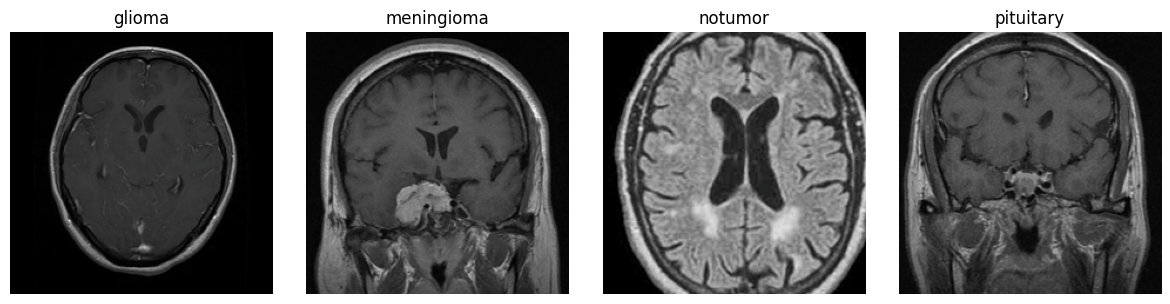

In [ ]:
class MRIDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(row['ruta']) as img:
            x = self.transform(img.convert('RGB'))
        return x, CLASS_TO_IDX[row['clase']]

generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(MRIDataset(train_df, prep), batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0, generator=generator)
val_loader = DataLoader(MRIDataset(val_df, prep), batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0)
test_loader = DataLoader(MRIDataset(test_df, prep), batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0)

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, clase in zip(axes, CLASES):
    ruta = train_df.loc[train_df.clase == clase, 'ruta'].iloc[0]
    with Image.open(ruta) as im:
        x = prep(im.convert('RGB'))
    visible = x * torch.tensor(data_config['std'])[:, None, None] + torch.tensor(data_config['mean'])[:, None, None]
    ax.imshow(visible.permute(1, 2, 0).clamp(0, 1))
    ax.set_title(clase); ax.axis('off')
plt.tight_layout(); plt.show()

En las cuatro muestras el cerebro queda completo después del recorte. Se aprecia además que las imágenes difieren en plano de corte, contraste y encuadre.

## 4.2.3 Fine-tuning con validación
En el fine-tuning se ajustan todos los pesos de la red, no solo la última capa. Para eso definimos tres elementos:
- **Función de pérdida (cross-entropy):** mide qué tan equivocadas son las predicciones; mientras más error, mayor la pérdida.
- **Optimizador (AdamW):** usa esa pérdida para corregir los pesos y mejorar la red. *weight_decay* evita que los pesos crezcan demasiado y que el modelo memorice.
- **evaluar_red:** función que prueba la red sobre un conjunto de imágenes sin modificar sus pesos y devuelve las predicciones, los scores y la pérdida. La usamos en validación y en prueba.

In [ ]:
#fine-tuning
criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(modelo.parameters(), lr=LR, weight_decay=1e-4)

def evaluar_red(red, loader):
    red.eval()
    reales, predichas, probabilidades = [], [], []
    total_loss = 0.0
    with torch.inference_mode():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            logits = red(x)
            total_loss += criterion(logits, y).item() * len(y)
            reales.extend(y.cpu().tolist())
            predichas.extend(logits.argmax(1).cpu().tolist())
            probabilidades.extend(logits.softmax(1).cpu().tolist())
    return np.array(reales), np.array(predichas), np.array(probabilidades), total_loss / len(loader.dataset)

###Ciclo de entrenamiento

En cada época:
1. *modelo.train()* activa el modo de entrenamiento y recorremos los lotes de entrenamiento.
2. Para cada lote calculamos la predicción, la pérdida, *backward()* calcula cómo cambiar los pesos y *optimizer.step()* los actualiza.
3. Al terminar la época, evaluamos en validación (sin actualizar pesos) y calculamos la pérdida y el F1 macro.
4. Si el F1 macro de validación mejora, guardamos una copia de los pesos (en CPU). Si no mejora durante *PATIENCE* épocas seguidas, se detiene el entrenamiento (parada temprana).

Al final se restauran los pesos de la **mejor época**, se guarda el historial en *historial.csv* y se grafican las curvas de pérdida y de F1 macro.

{'epoch': 1, 'train_loss': 0.5602608734820069, 'val_loss': 0.17516617459200678, 'val_f1_macro': 0.933992877366309}


{'epoch': 2, 'train_loss': 0.0649773949647651, 'val_loss': 0.13363068070085277, 'val_f1_macro': 0.9557398341279949}


{'epoch': 3, 'train_loss': 0.022109028288875433, 'val_loss': 0.14590633349227053, 'val_f1_macro': 0.9653696788916747}


{'epoch': 4, 'train_loss': 0.011156842320181132, 'val_loss': 0.1484334332868457, 'val_f1_macro': 0.9593753608661901}


{'epoch': 5, 'train_loss': 0.01313840273842059, 'val_loss': 0.13884605173952877, 'val_f1_macro': 0.9596486245025733}


{'epoch': 6, 'train_loss': 0.013270391467366829, 'val_loss': 0.13118234592534248, 'val_f1_macro': 0.96412645882139}
Parada temprana por falta de mejora en validación.
Mejor época: 3; F1 macro validación: 0.9654


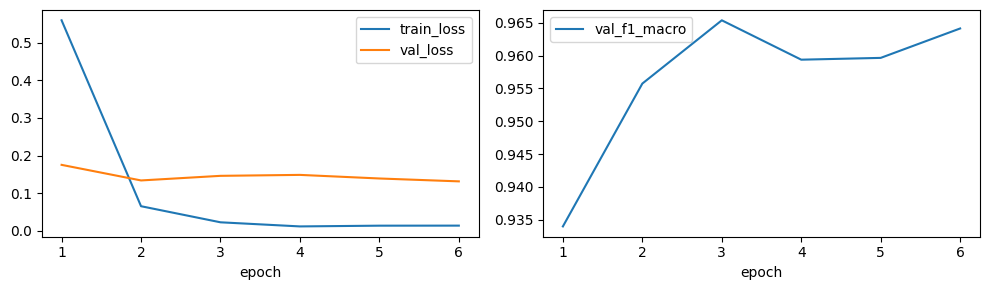

In [ ]:
history, best_f1, best_epoch, stale = [], -1.0, 0, 0
best_state = None
start_train = time.perf_counter()
for epoch in range(1, EPOCHS + 1):
    modelo.train()
    train_loss = 0.0
    for x, y in tqdm(train_loader, desc=f'Época {epoch}/{EPOCHS}'):
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        logits = modelo(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * len(y)
    y_val, p_val, _, val_loss = evaluar_red(modelo, val_loader)
    val_f1 = precision_recall_fscore_support(y_val, p_val, labels=LABELS,
        average='macro', zero_division=0)[2]
    history.append({'epoch': epoch, 'train_loss': train_loss / len(train_df),
                    'val_loss': val_loss, 'val_f1_macro': float(val_f1)})
    print(history[-1])
    if val_f1 > best_f1:
        best_f1, best_epoch, stale = float(val_f1), epoch, 0
        best_state = {k: v.detach().cpu().clone() for k, v in modelo.state_dict().items()}
    else:
        stale += 1
    if stale >= PATIENCE:
        print('Parada temprana por falta de mejora en validación.')
        break
train_seconds = time.perf_counter() - start_train

modelo.load_state_dict(best_state)
modelo.eval()
hist = pd.DataFrame(history)
hist.to_csv(OUT / 'historial.csv', index=False)
print(f'Mejor época: {best_epoch}; F1 macro validación: {best_f1:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
hist.plot(x='epoch', y=['train_loss', 'val_loss'], ax=axes[0])
hist.plot(x='epoch', y='val_f1_macro', ax=axes[1])
plt.tight_layout(); plt.savefig(OUT / 'curvas.png', dpi=150); plt.show()

###Resultado del entrenamiento
El entrenamiento se detuvo en la época 6 por parada temprana. La **mejor época fue la 3**, con F1 macro de validación de **0,9654**, y esos son los pesos que se usan de aquí en adelante. La pérdida de entrenamiento baja de 0,56 a cerca de 0,01, mientras que la de validación se estabiliza entre 0,13 y 0,15 desde la época 2: seguir entrenando mejora el ajuste a los datos de entrenamiento, pero no la validación.

## 4.2.4 Evaluación en prueba y línea base CLIP
**EfficientNet-B0.** Se evalúa el modelo con los pesos de la mejor época sobre todo *Testing*. La época se eligió solo con validación, por lo que la prueba no influyó en ninguna decisión. Se mide el tiempo de inferencia y luego se mueve el modelo a CPU para liberar memoria de la GPU antes de cargar CLIP.

In [ ]:
start = time.perf_counter()
y_test, pred_eff, prob_eff, _ = evaluar_red(modelo, test_loader)
eff_seconds = time.perf_counter() - start

modelo.to('cpu')
gc.collect()
if DEVICE.type == 'cuda': torch.cuda.empty_cache()

**CLIP zero-shot.** Relaciona imágenes con texto. Se le entrega cada imagen junto con cuatro descripciones, una por clase, y asigna la clase cuya descripción es más similar a la imagen. Las descripciones están en inglés, idioma principal del entrenamiento de CLIP. No usa las etiquetas ni modifica sus pesos, y tiene su propio procesador de imágenes, distinto al de EfficientNet.

Ambos modelos reciben las mismas imágenes de todo *Testing* en el mismo orden; los *assert* comprueban que las etiquetas y la cantidad de predicciones coinciden. Los scores de CLIP son softmax sobre la similitud entre imagen y texto, en el orden de *CLASES*.

In [ ]:
CLIP_ID = 'openai/clip-vit-base-patch32'
TEXTOS = {
    'glioma': 'a brain MRI scan showing a glioma tumor',
    'meningioma': 'a brain MRI scan showing a meningioma tumor',
    'notumor': 'a brain MRI scan with no tumor',
    'pituitary': 'a brain MRI scan showing a pituitary tumor',
}
clip_model = CLIPModel.from_pretrained(CLIP_ID).to(DEVICE).eval()
clip_processor = CLIPProcessor.from_pretrained(CLIP_ID)

clip_probs = []
start = time.perf_counter()
with torch.inference_mode():
    for begin in tqdm(range(0, len(test_df), BATCH_SIZE), desc='CLIP en test'):
        images = []
        for ruta in test_df.iloc[begin:begin + BATCH_SIZE]['ruta']:
            with Image.open(ruta) as im:
                images.append(im.convert('RGB'))
        inputs = clip_processor(text=[TEXTOS[c] for c in CLASES], images=images,
                                padding=True, return_tensors='pt').to(DEVICE)
        logits = clip_model(**inputs).logits_per_image
        clip_probs.extend(logits.softmax(dim=1).cpu().tolist())
clip_seconds = time.perf_counter() - start

prob_clip = np.array(clip_probs)
pred_clip = prob_clip.argmax(axis=1)
assert np.array_equal(y_test, test_df['clase'].map(CLASS_TO_IDX).to_numpy())
assert len(pred_clip) == len(pred_eff) == len(test_df)

del clip_model
gc.collect()
if DEVICE.type == 'cuda': torch.cuda.empty_cache()

## 4.2.5 Métricas y comparación de modelos
Definimos las métricas que usaremos:
- **Precisión:** de las imágenes predichas como una clase, cuántas realmente lo eran.
- **Recall:** de las imágenes reales de una clase, cuántas detectamos.
- **F1:** combina precisión y recall. Macro promedia las cuatro clases con el mismo peso; weighted las pondera por su cantidad de imágenes.
- **Accuracy balanceada:** promedio del recall de las clases.
- **Matriz de confusión:** cuántas imágenes de cada clase real se predijeron como cada clase.

La función *reportar* calcula las métricas globales y por clase, guarda las predicciones de cada imagen y los reportes en CSV, y grafica la matriz de confusión en cantidades y en proporción por clase real.

In [ ]:
def reportar(nombre, pred, probs, seconds):
    resumen = {'modelo': nombre, 'accuracy': accuracy_score(y_test, pred),
        'accuracy_balanceada': balanced_accuracy_score(y_test, pred),
        'inferencia_test_seg': seconds}
    for average in ['macro', 'weighted']:
        precision, recall, f1, _ = precision_recall_fscore_support(
            y_test, pred, labels=LABELS, average=average, zero_division=0)
        resumen.update({f'precision_{average}': precision,
                        f'recall_{average}': recall, f'f1_{average}': f1})
    reporte = pd.DataFrame(classification_report(y_test, pred, labels=LABELS,
        target_names=CLASES, output_dict=True, zero_division=0)).T
    print(nombre)
    display(reporte.round(4))
    tag = 'clip' if nombre.startswith('CLIP') else 'efficientnet'
    reporte.to_csv(OUT / f'metricas_por_clase_{tag}.csv')

    detalle = test_df.reset_index(drop=True).copy()
    detalle['prediccion'] = [CLASES[i] for i in pred]
    for i, c in enumerate(CLASES): detalle[f'score_{c}'] = probs[:, i]
    detalle.to_csv(OUT / f'predicciones_{tag}.csv', index=False)

    cm = confusion_matrix(y_test, pred, labels=LABELS)
    normalizada = cm / cm.sum(axis=1, keepdims=True)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, matriz, fmt, title in zip(axes, [cm, normalizada], ['d', '.1%'],
                                     ['Cantidad de imágenes', 'Proporción por clase real']):
        sns.heatmap(matriz, annot=True, fmt=fmt, cmap='Blues', ax=ax,
                    xticklabels=CLASES, yticklabels=CLASES)
        ax.set(xlabel='Predicción', ylabel='Clase real', title=title)
    fig.suptitle(nombre); plt.tight_layout()
    plt.savefig(OUT / f'matriz_{tag}.png', dpi=160); plt.show()
    return resumen

Se ejecuta *reportar* para ambos modelos, se arma la tabla comparativa (*comparacion_test.csv*) y se grafica accuracy, accuracy balanceada y F1 macro. También se calcula la diferencia de F1 macro entre EfficientNet y CLIP.

CLIP zero-shot


,precision,recall,f1-score,support
glioma,0.2207,0.3200,0.2612,400.0000
meningioma,0.2985,0.6150,0.4020,400.0000
notumor,0.8750,0.0525,0.0991,400.0000
pituitary,0.1337,0.0575,0.0804,400.0000
accuracy,0.2612,0.2612,0.2612,0.2612
macro avg,0.3820,0.2613,0.2107,1600.0000
weighted avg,0.3820,0.2612,0.2107,1600.0000


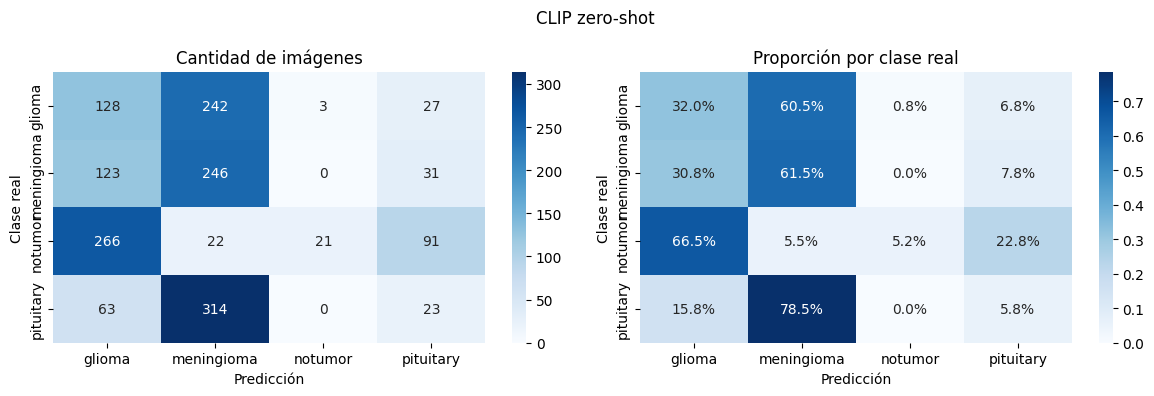

EfficientNet-B0 fine-tuning


,precision,recall,f1-score,support
glioma,0.9752,0.7875,0.8714,400.0000
meningioma,0.8981,0.9475,0.9221,400.0000
notumor,0.9174,1.0000,0.9569,400.0000
pituitary,0.9451,0.9900,0.9670,400.0000
accuracy,0.9312,0.9312,0.9312,0.9312
macro avg,0.9340,0.9312,0.9294,1600.0000
weighted avg,0.9340,0.9312,0.9294,1600.0000


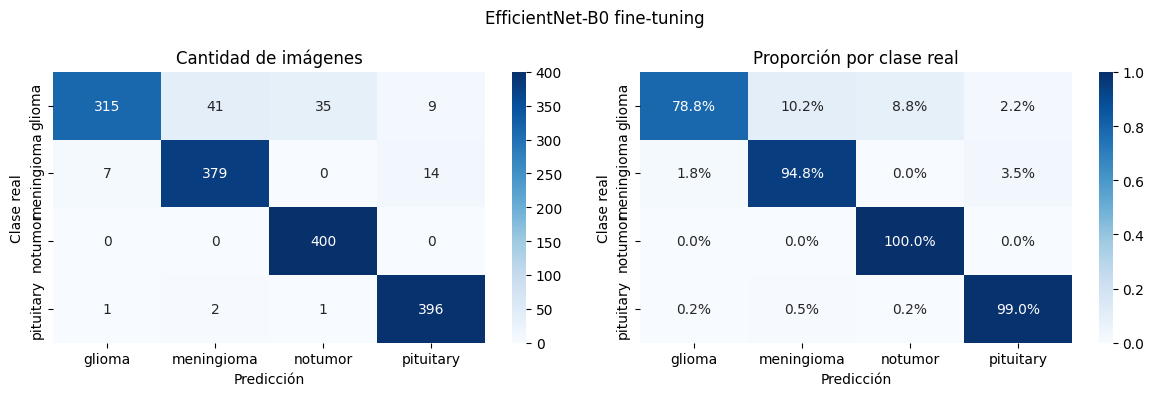

,modelo,accuracy,accuracy_balanceada,inferencia_test_seg,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,entrenamiento_seg
0,CLIP zero-shot,0.2612,0.2613,15.7632,0.382,0.2613,0.2107,0.382,0.2612,0.2107,0.0000
1,EfficientNet-B0 fine-tuning,0.9312,0.9312,16.9735,0.934,0.9312,0.9294,0.934,0.9312,0.9294,385.0969


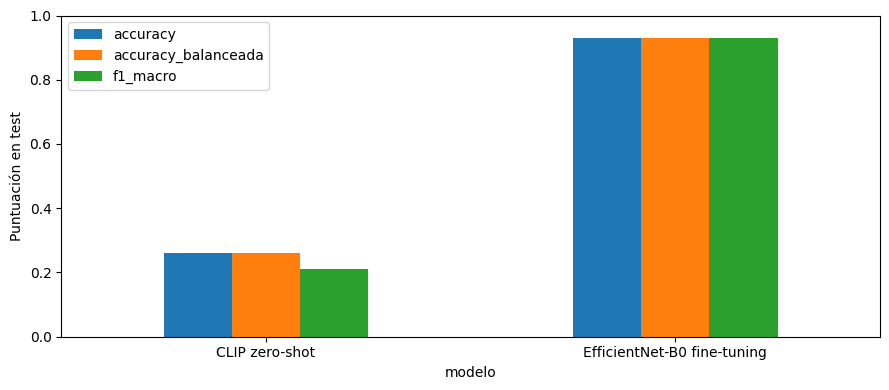

Diferencia F1 macro (EfficientNet − CLIP): +0.7187


In [ ]:
resultados = pd.DataFrame([
    reportar('CLIP zero-shot', pred_clip, prob_clip, clip_seconds),
    reportar('EfficientNet-B0 fine-tuning', pred_eff, prob_eff, eff_seconds)])
resultados['entrenamiento_seg'] = [0.0, train_seconds]
display(resultados.round(4))
resultados.to_csv(OUT / 'comparacion_test.csv', index=False)

resultados.set_index('modelo')[['accuracy', 'accuracy_balanceada', 'f1_macro']].plot.bar(
    ylim=(0, 1), figsize=(9, 4), rot=0, ylabel='Puntuación en test')
plt.tight_layout(); plt.savefig(OUT / 'comparacion.png', dpi=160); plt.show()

delta = resultados.iloc[1]['f1_macro'] - resultados.iloc[0]['f1_macro']
print(f'Diferencia F1 macro (EfficientNet − CLIP): {delta:+.4f}')

##Resultados en el conjunto de prueba (1.600 imágenes)

| Modelo | Accuracy | Accuracy balanceada | F1 macro |
|---|---|---|---|
| CLIP zero-shot | 0,2612 | 0,2613 | 0,2107 |
| **EfficientNet-B0 (fine-tuning)** | **0,9312** | **0,9312** | **0,9294** |

- **CLIP zero-shot** queda en un nivel cercano al azar (con cuatro clases balanceadas, adivinar da 25 %). Reconoce muy poco las clases *notumor* (recall 0,05) y *pituitary* (0,06). No fue entrenado con imágenes médicas y las descripciones de texto no bastan para distinguir estos tumores.
- **EfficientNet-B0** supera a CLIP por 0,72 en F1 macro (0,9294 frente a 0,2107). Esto justifica el *fine-tuning*: con 1.190 imágenes por clase, adaptar un modelo preentrenado rinde muchísimo más que usarlo sin entrenar.
- Por clase, EfficientNet-B0 tiene recall de 1,00 en *notumor*, 0,99 en *pituitary*, 0,95 en *meningioma* y *0,79 en glioma*, la clase más difícil. La precisión de *notumor* (0,92) baja porque 36 imágenes con tumor se predicen como *notumor*, y la de *meningioma* (0,90), la más baja, porque varios gliomas se confunden con meningioma.


## 4.2.6 Interpretación del error más costoso
Para este proyecto, el error más costoso es que una imagen **con tumor se prediga como notumor** (falso negativo): daría una falsa tranquilidad y podría retrasar una evaluación médica si el modelo se usara fuera del ámbito académico. Es una prioridad conceptual, no una estimación de costos clínicos. Confundir un tipo de tumor con otro también es relevante, y predecir tumor en una imagen *notumor* (falsa alarma) genera preocupación y estudios innecesarios, pero es menos grave.

Agrupamos las tres clases tumorales solo para analizar estos errores (el modelo sigue siendo de cuatro clases). La función calcula, para cada modelo, los falsos negativos (*tumor → notumor*), las falsas alarmas (*notumor → tumor*), el recall binario de tumor y la especificidad de *notumor*. Luego muestra hasta seis falsos negativos de EfficientNet, tomados en orden y sin elegirlos a mano.

,modelo,tumor_predicho_notumor_FN,notumor_predicho_tumor_FP,recall_tumor_binario,especificidad_notumor
0,CLIP,3,379,0.9975,0.0525
1,EfficientNet-B0,36,0,0.9700,1.0000


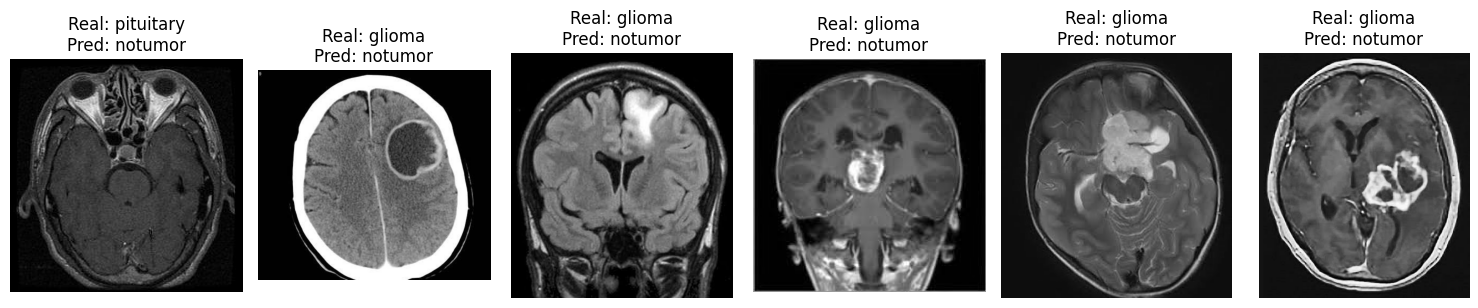

In [ ]:
NO_TUMOR = CLASS_TO_IDX['notumor']

def analizar_riesgo(nombre, pred):
    real_tumor = y_test != NO_TUMOR
    pred_tumor = pred != NO_TUMOR
    fn = int(np.sum(real_tumor & ~pred_tumor))
    fp = int(np.sum(~real_tumor & pred_tumor))
    tp = int(np.sum(real_tumor & pred_tumor))
    tn = int(np.sum(~real_tumor & ~pred_tumor))
    return {'modelo': nombre, 'tumor_predicho_notumor_FN': fn,
            'notumor_predicho_tumor_FP': fp,
            'recall_tumor_binario': tp / (tp + fn),
            'especificidad_notumor': tn / (tn + fp)}

riesgos = pd.DataFrame([analizar_riesgo('CLIP', pred_clip),
                       analizar_riesgo('EfficientNet-B0', pred_eff)])
display(riesgos)
riesgos.to_csv(OUT / 'errores_costosos.csv', index=False)

indices_fn = np.flatnonzero((y_test != NO_TUMOR) & (pred_eff == NO_TUMOR))
if len(indices_fn):
    fig, axes = plt.subplots(1, min(6, len(indices_fn)), figsize=(15, 3), squeeze=False)
    for ax, i in zip(axes.ravel(), indices_fn[:6]):
        with Image.open(test_df.iloc[i]['ruta']) as im: ax.imshow(im.convert('RGB'))
        ax.set_title(f'Real: {CLASES[y_test[i]]}\nPred: notumor'); ax.axis('off')
    plt.tight_layout(); plt.savefig(OUT / 'falsos_negativos.png', dpi=150); plt.show()
else:
    print('No hubo tumor → notumor en este test.')

###Interpretación
- **EfficientNet-B0** clasificó como *notumor* a **36 de las 1.200 imágenes con tumor (3,0 %)**, y **ninguna** de las 400 imágenes *notumor* como tumor (especificidad 1,00). De esos 36 falsos negativos, **35 son gliomas** y 1 es pituitary (según la matriz de confusión). El glioma es entonces la clase donde el modelo es más débil: solo reconoce correctamente 315 de 400 (78,8 %), y además confunde 41 con meningioma y 9 con pituitary.
- Los otros errores de EfficientNet son confusiones entre tipos de tumor (74 de sus 110 errores totales), principalmente glioma → meningioma (41) y meningioma → pituitary (14).
- **CLIP** parece tener menos falsos negativos (3), pero es engañoso: casi nunca predice *notumor* (379 de 400 imágenes sanas fueron marcadas como tumor, especificidad 0,05). Su recall de tumor es alto solo porque predice «tumor» para casi todo, y por eso no sirve como herramienta.
- **Consecuencia para la app:** un resultado *notumor* **no descarta un tumor**, en particular un glioma. La app debe mostrar siempre la confianza, aclarar que los scores softmax no son probabilidades clínicas calibradas, indicar que no reemplaza a un especialista y recomendar revisión médica ante cualquier sospecha.

## 4.2.7 Exportación del modelo y verificación de recarga
Guardamos un único archivo *.pt* (*brain_tumor_efficientnet_b0.pt*) con:
- el *state_dict* (los pesos de la mejor época),
- la arquitectura, el orden de las clases y la configuración de preprocesamiento,
- metadatos del entrenamiento (mejor época, F1 de validación, semilla, versiones) y los prompts de CLIP.


Para verificar la exportación, recargamos el modelo desde cero con *pretrained=False* (el conocimiento ya está en los pesos guardados, no hace falta volver a descargar ImageNet) y comprobamos con *assert_close* que su salida coincide con la del modelo original en una imagen. La función *predecir_imagen* es la que se trasladará a la app: recibe una imagen y devuelve la clase predicha y los scores por clase. También guardamos *config_app.json* con la configuración.

In [ ]:
checkpoint_path = OUT / 'brain_tumor_efficientnet_b0.pt'
config_export = {k: list(v) if isinstance(v, tuple) else v for k, v in data_config.items()}
checkpoint = {
    'architecture': MODEL_NAME, 'state_dict': best_state,
    'classes': CLASES, 'class_to_idx': CLASS_TO_IDX,
    'data_config': config_export, 'best_epoch': best_epoch,
    'best_val_f1_macro': best_f1, 'seed': SEED, 'versions': versions,
    'clip_prompts': TEXTOS,
}
torch.save(checkpoint, checkpoint_path)

ckpt = torch.load(checkpoint_path, map_location='cpu', weights_only=True)
modelo_app = timm.create_model(ckpt['architecture'], pretrained=False,
                             num_classes=len(ckpt['classes']))
modelo_app.load_state_dict(ckpt['state_dict'], strict=True)
modelo_app.eval()
prep_app = create_transform(**ckpt['data_config'], is_training=False)

def predecir_imagen(ruta):
    with Image.open(ruta) as im:
        x = prep_app(im.convert('RGB')).unsqueeze(0)
    with torch.inference_mode():
        scores = modelo_app(x).softmax(dim=1)[0]
    return {'clase': ckpt['classes'][scores.argmax().item()],
            'scores': dict(zip(ckpt['classes'], scores.tolist()))}

with Image.open(test_df.iloc[0]['ruta']) as im:
    sample = prep_app(im.convert('RGB')).unsqueeze(0)
with torch.inference_mode():
    modelo.eval()
    torch.testing.assert_close(modelo(sample), modelo_app(sample), rtol=1e-5, atol=1e-6)
print('Recarga verificada. Archivo:', checkpoint_path)
print('Tamaño MB:', round(checkpoint_path.stat().st_size / 1024**2, 2))
print(predecir_imagen(test_df.iloc[0]['ruta']))
_ = (OUT / 'config_app.json').write_text(json.dumps(
    {k: v for k, v in checkpoint.items() if k != 'state_dict'}, indent=2), encoding='utf-8')

Recarga verificada. Archivo: /content/resultados_4_2/brain_tumor_efficientnet_b0.pt
Tamaño MB: 15.58
{'clase': 'pituitary', 'scores': {'glioma': 0.001557221869006753, 'meningioma': 0.02063821628689766, 'notumor': 2.405045961495489e-05, 'pituitary': 0.9777805209159851}}


## 4.2.8 Descarga de resultados
Comprimimos la carpeta de resultados en un ZIP y lo descargamos. Incluye el modelo *.pt* para la app, las métricas, las predicciones, los manifiestos del split, las curvas y las matrices de confusión.

In [ ]:
from google.colab import files
zip_path = shutil.make_archive('/content/entrega_brain_tumor_4_2', 'zip', OUT)
files.download(zip_path)

---
## Conclusiones del punto 4.2
- Siguiendo el árbol de decisión de la clase aplicamos fine-tuning de EfficientNet-B0, que alcanzó 93,1 % de accuracy y 0,929 de F1 macro en prueba, frente a 26,1 % y 0,211 de CLIP zero-shot.
- El modelo detecta casi todas las imágenes *notumor* (recall 1,00) y *pituitary* (0,99); su punto débil es el *glioma* (recall 78,8 %), que concentra 35 de los 36 casos donde un tumor se predice como *notumor*. Ese es el error más costoso para el problema.
- Exportamos el modelo, las clases y el preprocesamiento en un *.pt* verificado, listo para integrarse en la app web del punto 4.3.

## Referencias
- Nickparvar, M. (2026). *Brain Tumor MRI Dataset* [Conjunto de datos]. Kaggle. https://doi.org/10.34740/KAGGLE/DSV/14832123
